# Compare round 1 and round 2 without retraining
Run all nine code cells in order, or choose Run All. This notebook runs inference only: it does not train, overwrite checkpoints, or change the model used by notebooks 03/04.

First, it measures both checkpoints on the SAME combined validation split at confidence thresholds from 0.10 to 0.95 (including 0.25). A true positive requires the correct class and bounding-box IoU >= 0.50. Negative false-positive rate counts images with any detection. It selects the threshold with the lowest false-positive rate while retaining >= 90% recall for both target classes, breaking ties in favor of higher minimum recall and then a lower threshold.

If no threshold preserves both recalls, it retains 0.25 for comparison and reports that calibration failed. A selected threshold is a candidate, not a production approval: we also check the <= 5% negative false-positive target and report metrics by dataset. No held-out test or phone photos are used to select thresholds.

Then it compares both models on the uploaded phone photos, using each model's validation-selected threshold. The photo table and paired boxes are a small sanity check, not detection mAP or a guarantee. Confidence is not capture quality. This experiment should help decide which model to keep; it does not automatically replace either model.

The assistant has not executed any cells. Progress and timing are printed during validation.

Finally, the MIDV-2020 section evaluates the downloaded photo archive at the validation-selected thresholds. It reports passport recall and negative false positives separately, with no driving-licence examples. See that section for the shared-design limitation.

The final held-back test section compares both checkpoints on the same MIDV-500/MIDV-2019 test split using the validation-selected thresholds. Run its two cells alone if setup and threshold-selection results are already available in the kernel. Failure summaries include image paths for inspection.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import timedelta
import json
import time
import numpy as np
import torch
from ultralytics import YOLO
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

PROJECT = Path('/home/joe/PycharmProjects/id-capture')
ROUND2_DATA = PROJECT / 'training/data/midv_round2_all_frames'
RAW = PROJECT / 'training/data/raw'
first = json.loads((PROJECT / 'training/data/midv500_yolo/latest_run.json').read_text())
second = json.loads((ROUND2_DATA / 'latest_run.json').read_text())
CHECKPOINTS = {'Round 1': Path(first['best']), 'Round 2': Path(second['best'])}
assert all(path.is_file() for path in CHECKPOINTS.values()), CHECKPOINTS
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
THRESHOLDS = np.round(np.arange(0.10, 1.0, 0.05), 2)
MIN_RECALL = 0.90
MAX_NEGATIVE_FP = 0.05
BATCH = 16
IMGSZ = 640
NAMES = {0: 'driving_licence', 1: 'passport'}
manifest = json.loads((ROUND2_DATA / 'manifest.json').read_text())
val_records = [r for r in manifest['records'] if r['split'] == 'val']
assert val_records and {r['class'] for r in val_records} == {0, 1, None}
assert all(Path(r['image']).is_file() and Path(r['label']).is_file() for r in val_records)
for name, checkpoint in CHECKPOINTS.items():
    print(name, checkpoint)
print('Device:', torch.cuda.get_device_name(0) if DEVICE == 0 else 'CPU')
print('Validation images:', len(val_records), dict(Counter(r['class'] for r in val_records)))
print('Thresholds:', THRESHOLDS.tolist())

def show_table(rows):
    columns = list(rows[0])
    table = '<table><thead><tr>' + ''.join('<th>' + escape(c) + '</th>' for c in columns) + '</tr></thead><tbody>'
    for row in rows:
        table += '<tr>' + ''.join('<td>' + escape(str(row[c])) + '</td>' for c in columns) + '</tr>'
    display(HTML(table + '</tbody></table>'))

def box_iou(boxes, target):
    overlap = np.maximum(0, np.minimum(boxes[:, 2:], target[2:]) - np.maximum(boxes[:, :2], target[:2]))
    intersection = overlap.prod(axis=1)
    areas = np.maximum(0, boxes[:, 2:] - boxes[:, :2]).prod(axis=1)
    target_area = np.maximum(0, target[2:] - target[:2]).prod()
    return intersection / np.maximum(areas + target_area - intersection, 1e-9)


Round 1 /home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt
Round 2 /home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv_round2_all_frames_20261012_121808_755987/weights/best.pt
Device: NVIDIA GeForce RTX 5060 Ti
Validation images: 4162 {None: 2073, 1: 1250, 0: 839}
Thresholds: [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]


In [2]:
# Predict once per model; evaluate cached boxes at each higher confidence.
sources = ('combined', 'midv500', 'midv2019')
totals = Counter()
for rec in val_records:
    for source in ('combined', rec['source']):
        totals[(source, rec['class'])] += 1
sweeps = {}
for model_name, checkpoint in CHECKPOINTS.items():
    candidate = YOLO(str(checkpoint))
    assert candidate.names == NAMES
    hits = Counter()
    false_positives = Counter()
    started = time.perf_counter()
    for offset in range(0, len(val_records), BATCH):
        records = val_records[offset:offset + BATCH]
        predictions = candidate.predict(
            source=[r['image'] for r in records], device=DEVICE,
            imgsz=IMGSZ, conf=float(THRESHOLDS[0]), verbose=False,
        )
        assert len(predictions) == len(records)
        for rec, prediction in zip(records, predictions):
            cls = rec['class']
            boxes = prediction.boxes
            scores = boxes.conf.cpu().numpy()
            classes = boxes.cls.cpu().numpy().astype(int)
            if cls is not None:
                cx, cy, bw, bh = map(float, Path(rec['label']).read_text().split()[1:])
                target = np.array([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2])
                localized = (classes == cls) & (box_iou(boxes.xyxyn.cpu().numpy(), target) >= 0.50)
            for threshold in THRESHOLDS:
                selected = scores >= threshold
                for source in ('combined', rec['source']):
                    if cls is None:
                        false_positives[(source, threshold)] += int(selected.any())
                    else:
                        hits[(source, threshold, cls)] += int((selected & localized).any())
        if offset % (BATCH * 20) == 0 or offset + BATCH >= len(val_records):
            done = min(offset + BATCH, len(val_records))
            elapsed = time.perf_counter() - started
            eta = elapsed / done * (len(val_records) - done)
            print(f'{model_name}: {100 * done / len(val_records):.1f}% | Elapsed: {timedelta(seconds=int(elapsed))} | ETA: {timedelta(seconds=int(eta))}', flush=True)
    sweeps[model_name] = []
    for threshold in THRESHOLDS:
        metrics = {}
        for source in sources:
            metrics[source] = {
                'licence_recall': hits[(source, threshold, 0)] / totals[(source, 0)],
                'passport_recall': hits[(source, threshold, 1)] / totals[(source, 1)],
                'negative_fp': false_positives[(source, threshold)] / totals[(source, None)],
            }
        sweeps[model_name].append({'threshold': float(threshold), 'metrics': metrics})
    del candidate
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

table_rows = []
for model_name, sweep in sweeps.items():
    for row in sweep:
        metric = row['metrics']['combined']
        table_rows.append({
            'Model': model_name, 'Threshold': f'{row["threshold"]:.2f}',
            'Licence recall': f'{metric["licence_recall"]:.1%}',
            'Passport recall': f'{metric["passport_recall"]:.1%}',
            'Negative FP': f'{metric["negative_fp"]:.1%}',
        })
show_table(table_rows)


Round 1: 0.4% | Elapsed: 0:00:04 | ETA: 0:21:03
Round 1: 8.1% | Elapsed: 0:00:06 | ETA: 0:01:15
Round 1: 15.8% | Elapsed: 0:00:08 | ETA: 0:00:45
Round 1: 23.5% | Elapsed: 0:00:10 | ETA: 0:00:34
Round 1: 31.1% | Elapsed: 0:00:12 | ETA: 0:00:26
Round 1: 38.8% | Elapsed: 0:00:14 | ETA: 0:00:22
Round 1: 46.5% | Elapsed: 0:00:15 | ETA: 0:00:18
Round 1: 54.2% | Elapsed: 0:00:17 | ETA: 0:00:14
Round 1: 61.9% | Elapsed: 0:00:19 | ETA: 0:00:11
Round 1: 69.6% | Elapsed: 0:00:21 | ETA: 0:00:09
Round 1: 77.3% | Elapsed: 0:00:22 | ETA: 0:00:06
Round 1: 85.0% | Elapsed: 0:00:24 | ETA: 0:00:04
Round 1: 92.6% | Elapsed: 0:00:26 | ETA: 0:00:02
Round 1: 100.0% | Elapsed: 0:00:28 | ETA: 0:00:00
Round 2: 0.4% | Elapsed: 0:00:00 | ETA: 0:00:43
Round 2: 8.1% | Elapsed: 0:00:01 | ETA: 0:00:21
Round 2: 15.8% | Elapsed: 0:00:03 | ETA: 0:00:19
Round 2: 23.5% | Elapsed: 0:00:05 | ETA: 0:00:17
Round 2: 31.1% | Elapsed: 0:00:07 | ETA: 0:00:15
Round 2: 38.8% | Elapsed: 0:00:08 | ETA: 0:00:14
Round 2: 46.5% | Elapse

Model,Threshold,Licence recall,Passport recall,Negative FP
Round 1,0.10,95.1%,99.0%,19.2%
Round 1,0.15,94.4%,98.9%,16.4%
Round 1,0.20,93.3%,98.9%,14.5%
Round 1,0.25,93.0%,98.6%,13.1%
Round 1,0.30,92.1%,98.4%,12.0%
Round 1,0.35,92.0%,98.4%,10.6%
Round 1,0.40,91.3%,98.3%,9.8%
Round 1,0.45,90.9%,98.2%,8.6%
Round 1,0.50,90.2%,98.2%,8.0%
Round 1,0.55,89.7%,97.9%,6.6%


In [3]:
chosen = {}
selection_rows = []
for model_name, sweep in sweeps.items():
    eligible = [
        row for row in sweep
        if row['metrics']['combined']['licence_recall'] >= MIN_RECALL
        and row['metrics']['combined']['passport_recall'] >= MIN_RECALL
    ]
    if eligible:
        selected = min(eligible, key=lambda row: (
            row['metrics']['combined']['negative_fp'],
            -min(row['metrics']['combined']['licence_recall'], row['metrics']['combined']['passport_recall']),
            row['threshold'],
        ))
        calibrated = True
    else:
        selected = next(row for row in sweep if np.isclose(row['threshold'], 0.25))
        calibrated = False
        print(model_name, ': no threshold preserved >= 90% recall for both classes. Using 0.25 for photo comparison.')
    chosen[model_name] = {**selected, 'calibrated': calibrated}
    for source in sources:
        metric = selected['metrics'][source]
        targets_met = calibrated and metric['licence_recall'] >= MIN_RECALL and metric['passport_recall'] >= MIN_RECALL and metric['negative_fp'] <= MAX_NEGATIVE_FP
        selection_rows.append({
            'Model': model_name, 'Source': source, 'Threshold': f'{selected["threshold"]:.2f}',
            'Licence recall': f'{metric["licence_recall"]:.1%}',
            'Passport recall': f'{metric["passport_recall"]:.1%}',
            'Negative FP': f'{metric["negative_fp"]:.1%}',
            'Targets met': 'YES' if targets_met else 'NO',
        })
show_table(selection_rows)
print('Thresholds were selected on validation only. Neither checkpoint nor any deployment setting was changed.')


Model,Source,Threshold,Licence recall,Passport recall,Negative FP,Targets met
Round 1,combined,0.50,90.2%,98.2%,8.0%,NO
Round 1,midv500,0.50,97.0%,98.7%,5.3%,NO
Round 1,midv2019,0.50,73.3%,96.9%,14.5%,NO
Round 2,combined,0.80,93.2%,90.3%,2.9%,YES
Round 2,midv500,0.80,94.7%,87.8%,0.6%,NO
Round 2,midv2019,0.80,89.6%,96.7%,8.5%,NO


Thresholds were selected on validation only. Neither checkpoint nor any deployment setting was changed.


In [4]:
extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp', '.webp'}
phone_samples = []
for expected in ('passport', 'driving_licence', 'none'):
    folder = RAW / expected
    if folder.is_dir():
        phone_samples.extend((p, expected) for p in sorted(folder.iterdir()) if p.is_file() and p.suffix.lower() in extensions)
assert phone_samples, 'No uploaded photos found.'
phone_rows = []
phone_predictions = {}
for model_name, checkpoint in CHECKPOINTS.items():
    candidate = YOLO(str(checkpoint))
    threshold = chosen[model_name]['threshold']
    for path, expected in phone_samples:
        with Image.open(path) as original:
            rgb = np.asarray(ImageOps.exif_transpose(original).convert('RGB'))
        prediction = candidate.predict(
            source=np.ascontiguousarray(rgb[..., ::-1]), device=DEVICE,
            imgsz=IMGSZ, conf=threshold, verbose=False,
        )[0]
        boxes = prediction.boxes
        if len(boxes):
            top = int(boxes.conf.argmax().item())
            predicted = prediction.names[int(boxes.cls[top].item())]
            confidence = f'{float(boxes.conf[top].item()):.1%}'
        else:
            predicted, confidence = 'none', 'N/A'
        phone_rows.append({
            'Photo': path.name, 'Expected': expected, 'Model': model_name,
            'Threshold': f'{threshold:.2f}', 'Predicted': predicted,
            'Confidence': confidence, 'Type match': 'YES' if expected == predicted else 'NO',
            'Detections': len(boxes),
        })
        phone_predictions[(model_name, str(path))] = prediction
    del candidate
show_table(phone_rows)
for model_name in CHECKPOINTS:
    rows = [r for r in phone_rows if r['Model'] == model_name]
    matches = sum(r['Type match'] == 'YES' for r in rows)
    print(f'{model_name}: {matches}/{len(rows)} phone-photo type matches at confidence {chosen[model_name]["threshold"]:.2f}.')
print('A type match does not establish correct cropping; inspect the boxes in the next cell.')


Photo,Expected,Model,Threshold,Predicted,Confidence,Type match,Detections
passport1.jpg,passport,Round 1,0.50,passport,89.1%,YES,1
passport2.jpg,passport,Round 1,0.50,passport,87.9%,YES,1
passport3.jpg,passport,Round 1,0.50,passport,70.0%,YES,1
driving_licence1.jpg,driving_licence,Round 1,0.50,driving_licence,89.1%,YES,1
driving_licence2.jpg,driving_licence,Round 1,0.50,driving_licence,77.1%,YES,1
none1.jpg,none,Round 1,0.50,none,N/A,YES,0
none2.jpg,none,Round 1,0.50,none,N/A,YES,0
none3.jpg,none,Round 1,0.50,none,N/A,YES,0
none4.jpg,none,Round 1,0.50,none,N/A,YES,0
passport1.jpg,passport,Round 2,0.80,passport,82.2%,YES,1


Round 1: 9/9 phone-photo type matches at confidence 0.50.
Round 2: 7/9 phone-photo type matches at confidence 0.80.
A type match does not establish correct cropping; inspect the boxes in the next cell.


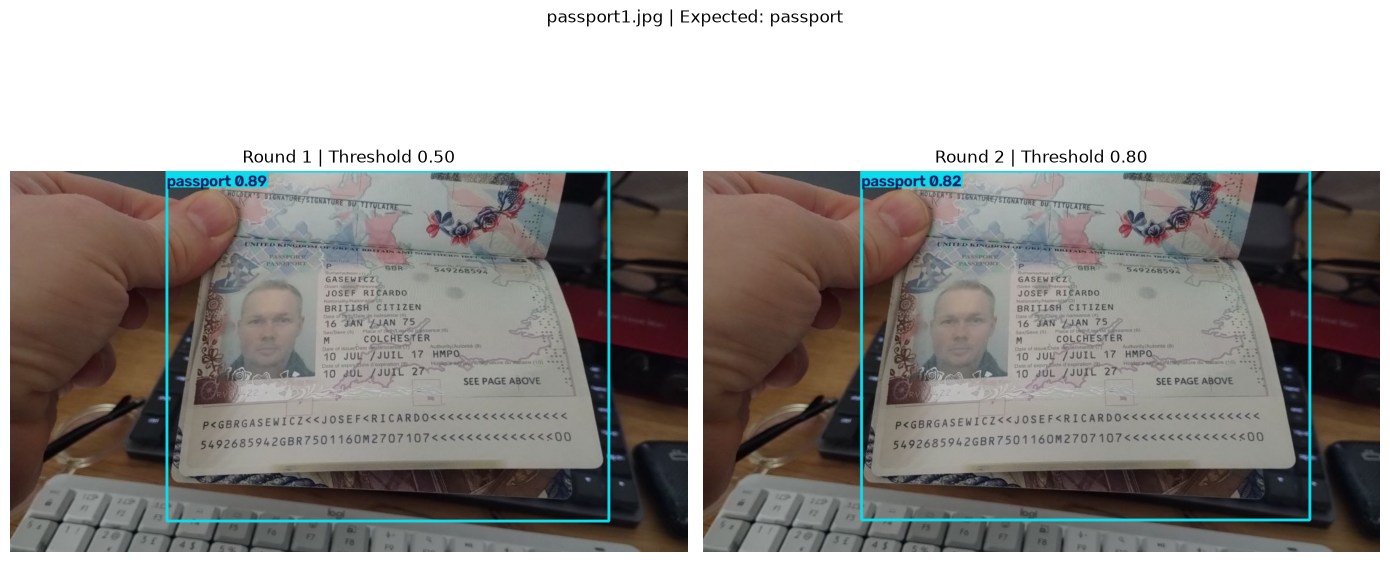

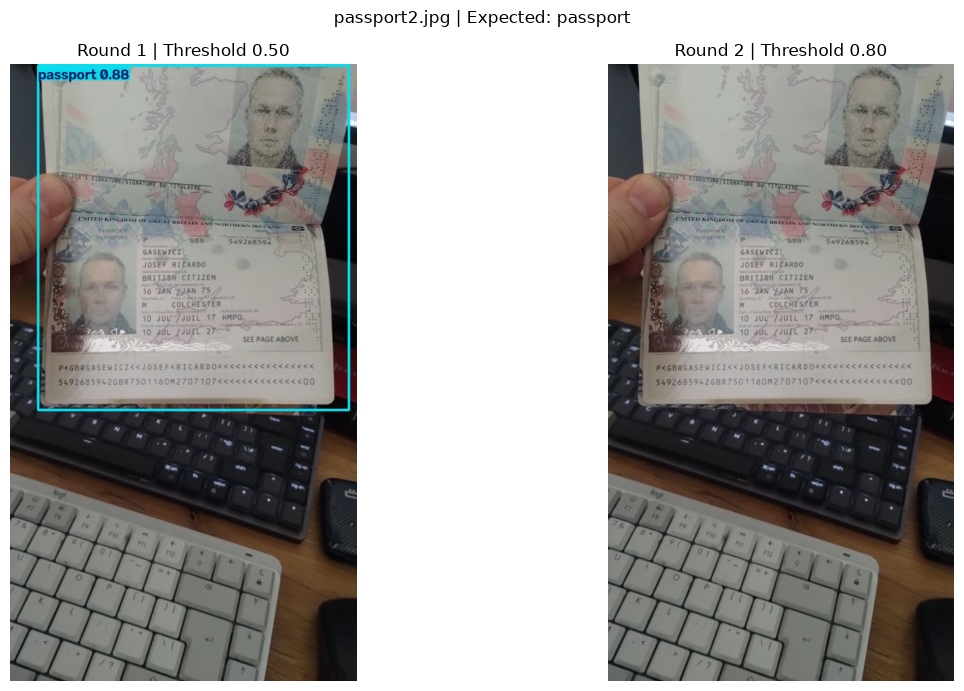

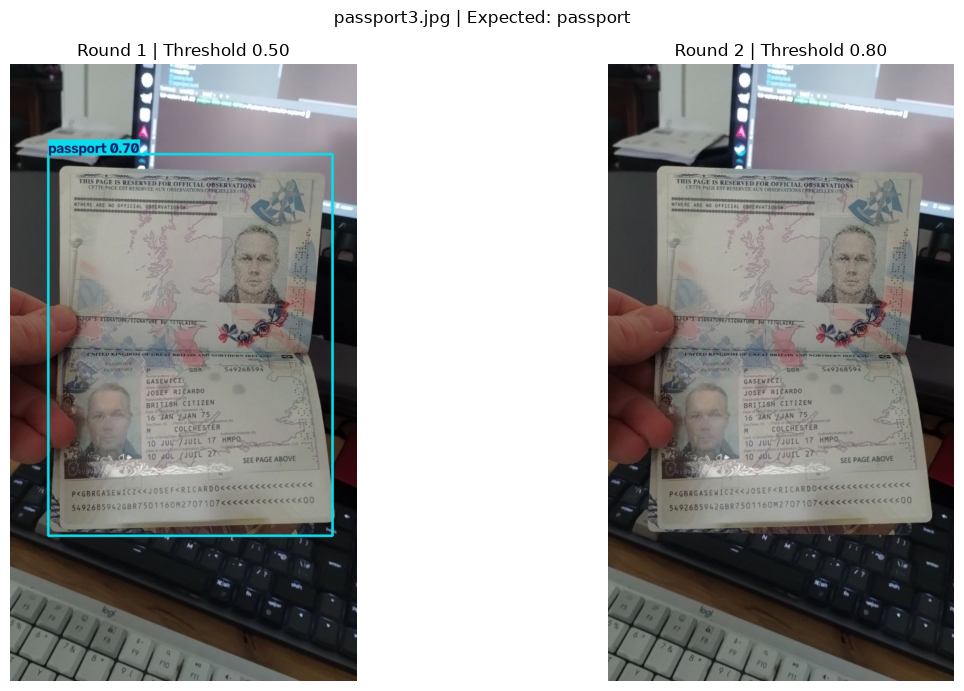

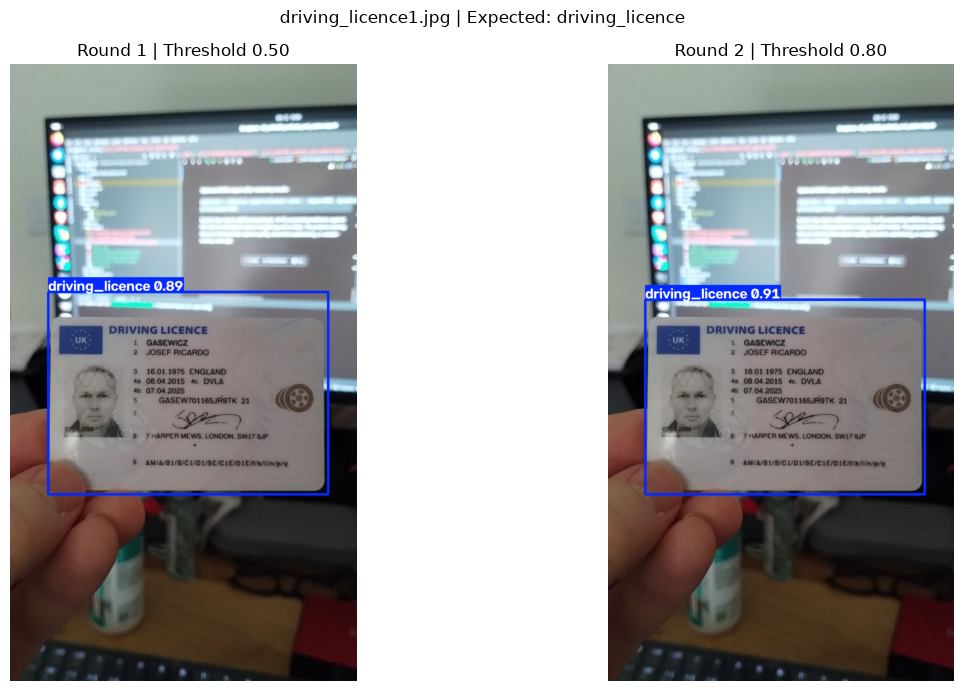

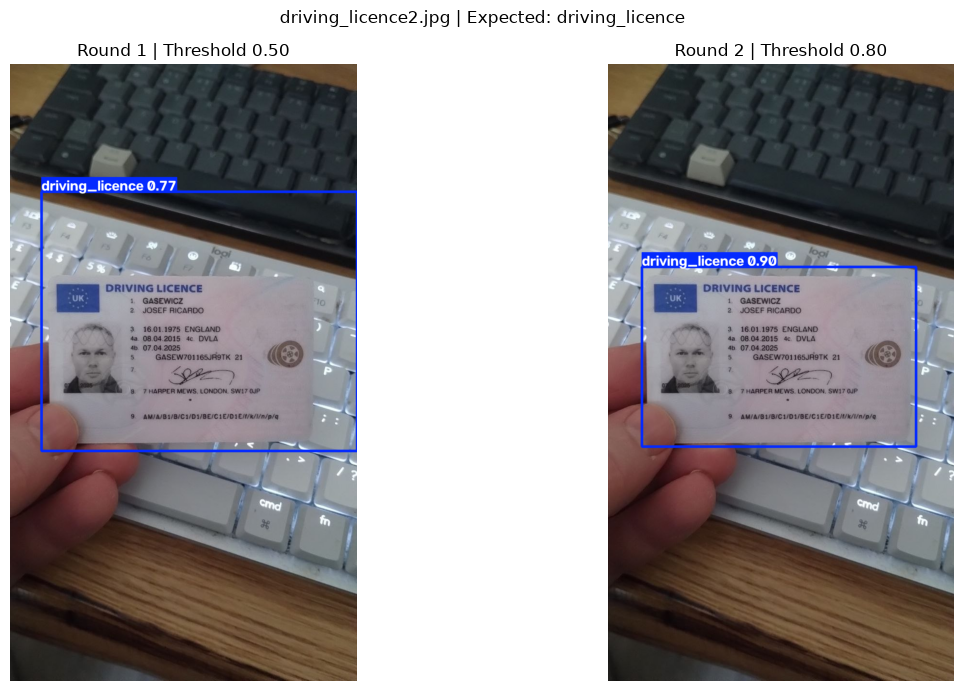

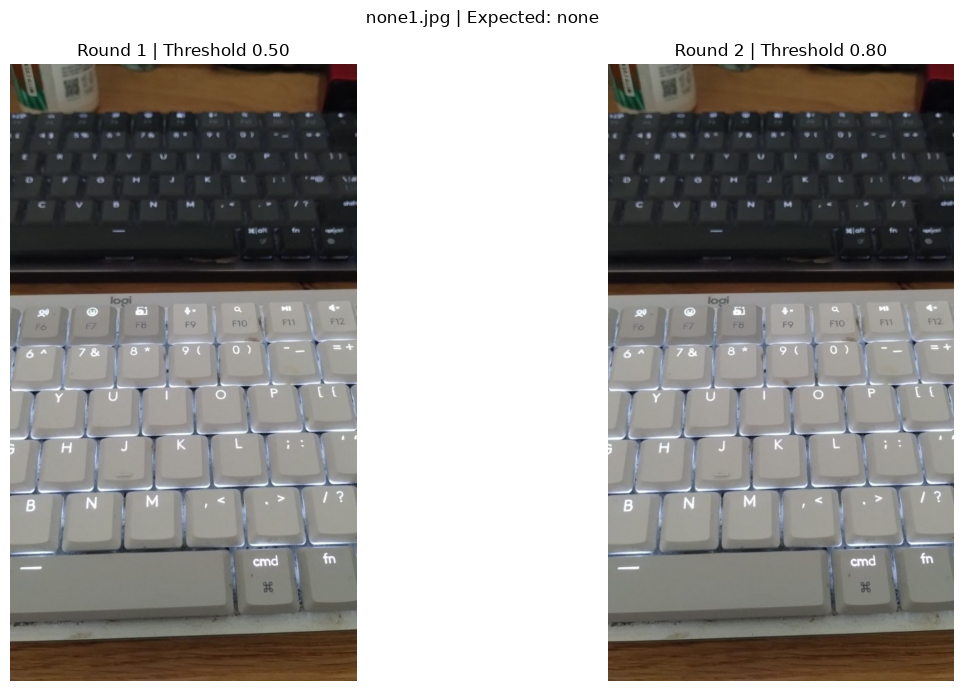

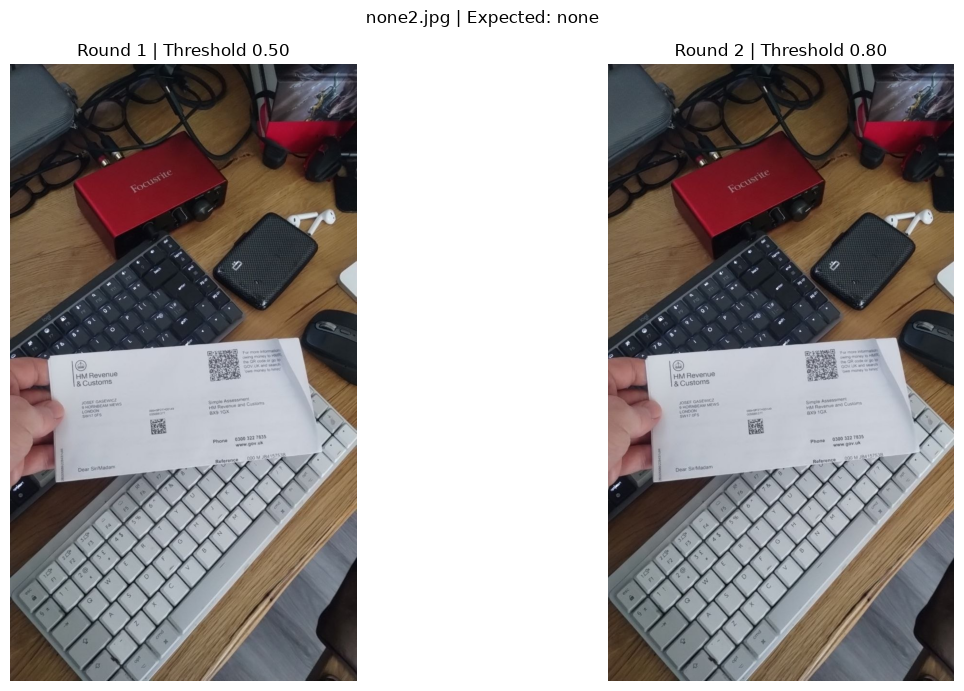

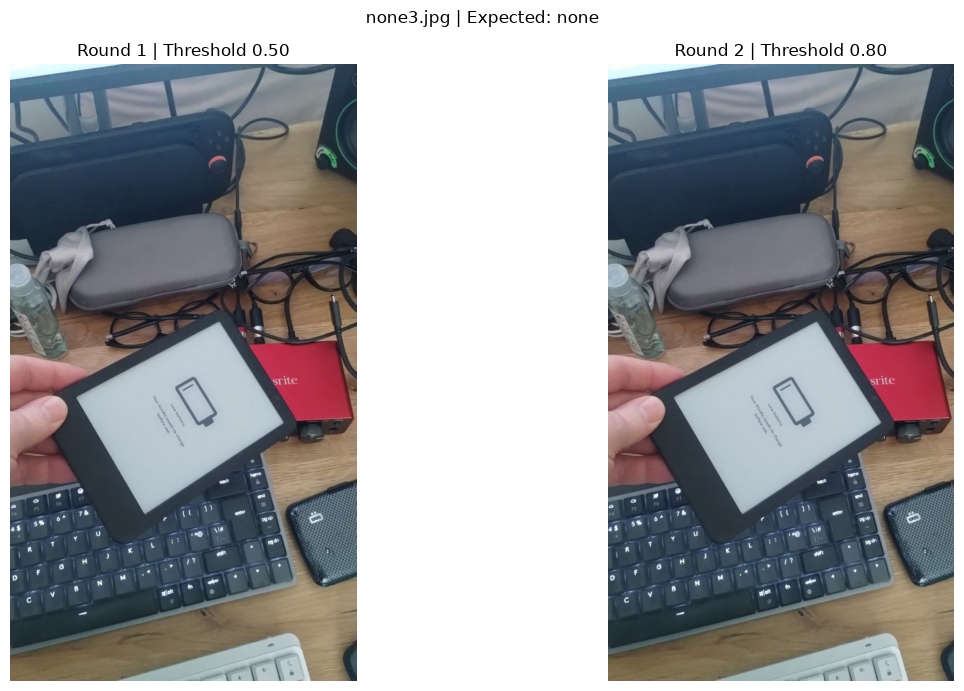

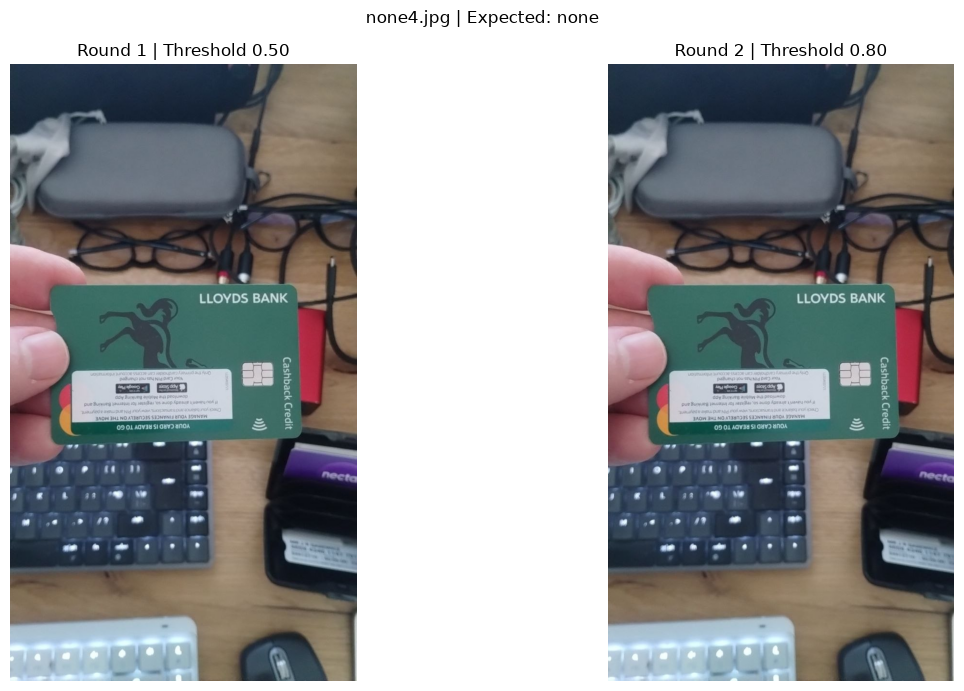

In [5]:
for path, expected in phone_samples:
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, model_name in zip(axes, CHECKPOINTS):
        prediction = phone_predictions[(model_name, str(path))]
        ax.imshow(prediction.plot()[..., ::-1])
        ax.set_title(f'{model_name} | Threshold {chosen[model_name]["threshold"]:.2f}')
        ax.axis('off')
    fig.suptitle(f'{path.name} | Expected: {expected}')
    plt.tight_layout()
    plt.show()


## MIDV-2020 photo comparison at fixed thresholds
Run the two code cells below after the existing threshold-selection cell. This evaluates 400 international passports and 600 negatives directly from `/home/joe/training-data/midv2020/photo.tar`, without extraction or training. Russian internal passports remain negatives under the existing class definitions. There are no driving licences, so licence recall cannot be measured.

Use the validation-selected threshold for each model; do not tune thresholds using these results. Several document designs overlap the earlier datasets, although these are new physical samples: this is an additional stress test, not a benchmark of entirely unseen designs. Results are separate from the original validation and phone-photo comparisons. Images are read one at a time and resized to a maximum side of 960, matching the existing prepared data. Neither new code cell has been executed by the assistant.

In [6]:
import gc
import tarfile

MIDV2020_ARCHIVE = Path('/home/joe/training-data/midv2020/photo.tar')
MIDV2020_PASSPORT_TYPES = {
    'aze_passport', 'grc_passport', 'lva_passport', 'srb_passport',
}
assert MIDV2020_ARCHIVE.is_file(), MIDV2020_ARCHIVE
assert 'chosen' in globals(), 'Run the existing threshold-selection cell first.'
assert set(chosen) == set(CHECKPOINTS)

midv2020_samples = []
with tarfile.open(MIDV2020_ARCHIVE, 'r:') as archive:
    for member in archive.getmembers():
        if not (member.isfile() and member.name.startswith('annotations/')
                and member.name.endswith('.json')):
            continue
        code = Path(member.name).stem
        with archive.extractfile(member) as source:
            annotations = json.load(source)
        for annotation in annotations['_via_img_metadata'].values():
            filename = annotation['filename']
            image_member = f'images/{code}/{filename}'
            assert archive.getmember(image_member).isfile(), image_member
            quad = None
            if code in MIDV2020_PASSPORT_TYPES:
                regions = annotation['regions']
                if isinstance(regions, dict):
                    regions = regions.values()
                shapes = [
                    region['shape_attributes'] for region in regions
                    if region['region_attributes'].get('field_name') == 'doc_quad'
                ]
                assert len(shapes) == 1, image_member
                shape = shapes[0]
                quad = np.column_stack((
                    shape['all_points_x'], shape['all_points_y'],
                )).astype(float)
                assert quad.shape == (4, 2) and np.isfinite(quad).all(), image_member
            midv2020_samples.append({
                'code': code, 'member': image_member,
                'passport': code in MIDV2020_PASSPORT_TYPES, 'quad': quad,
            })

midv2020_samples.sort(key=lambda sample: sample['member'])
assert len({sample['member'] for sample in midv2020_samples}) == 1000
assert sum(sample['passport'] for sample in midv2020_samples) == 400
assert len(midv2020_samples) == 1000
midv2020_thresholds = {
    name: float(chosen[name]['threshold']) for name in CHECKPOINTS
}
print('MIDV-2020: 400 passports, 600 negatives; no driving licences.')
print('Fixed validation-selected thresholds:', midv2020_thresholds)
print('One image at a time; maximum side 960; inference size:', IMGSZ)


MIDV-2020: 400 passports, 600 negatives; no driving licences.
Fixed validation-selected thresholds: {'Round 1': 0.5, 'Round 2': 0.8}
One image at a time; maximum side 960; inference size: 640


In [7]:
def evaluate_midv2020(checkpoint, model_name, threshold):
    model = YOLO(str(checkpoint))
    assert model.names == NAMES
    counts, hits, false_positives = Counter(), Counter(), Counter()
    started = time.perf_counter()
    try:
        with tarfile.open(MIDV2020_ARCHIVE, 'r:') as archive:
            for index, sample in enumerate(midv2020_samples, 1):
                with archive.extractfile(sample['member']) as source:
                    with Image.open(source) as original:
                        # VIA annotations use the EXIF-corrected display orientation.
                        upright = ImageOps.exif_transpose(original)
                        try:
                            image = upright.convert('RGB')
                        finally:
                            upright.close()
                        width, height = image.size
                try:
                    image.thumbnail((960, 960))
                    prediction = model.predict(
                        source=image, device=DEVICE, imgsz=IMGSZ,
                        conf=threshold, verbose=False,
                    )[0]
                    boxes = prediction.boxes
                    matched = False
                    if sample['passport']:
                        quad = sample['quad']
                        lo = np.maximum(quad.min(axis=0), [0, 0])
                        hi = np.minimum(quad.max(axis=0), [width, height])
                        assert np.all(hi > lo), sample['member']
                        target = np.r_[lo / [width, height], hi / [width, height]]
                        classes = boxes.cls.cpu().numpy().astype(int)
                        matched = bool(np.any(
                            (classes == 1)
                            & (box_iou(boxes.xyxyn.cpu().numpy(), target) >= 0.50)
                        ))
                        del classes
                    for group in ('combined', sample['code']):
                        counts[(group, sample['passport'])] += 1
                        if sample['passport']:
                            hits[group] += int(matched)
                        else:
                            false_positives[group] += int(len(boxes) > 0)
                    del prediction, boxes
                finally:
                    image.close()
                if index % 100 == 0 or index == len(midv2020_samples):
                    elapsed = time.perf_counter() - started
                    eta = elapsed / index * (len(midv2020_samples) - index)
                    print(
                        f'{model_name} MIDV-2020: {index}/{len(midv2020_samples)}'
                        f' | Elapsed: {timedelta(seconds=int(elapsed))}'
                        f' | ETA: {timedelta(seconds=int(eta))}',
                        flush=True,
                    )
        rows = []
        for group in ['combined'] + sorted({s['code'] for s in midv2020_samples}):
            positives = counts[(group, True)]
            negatives = counts[(group, False)]
            recall = hits[group] / positives if positives else None
            negative_fp = false_positives[group] / negatives if negatives else None
            rows.append({
                'Model': model_name, 'Source': group,
                'Threshold': f'{threshold:.2f}',
                'Passports': positives, 'Negatives': negatives,
                'Passport hits': hits[group],
                'False-positive images': false_positives[group],
                'Passport recall': f'{recall:.1%}' if recall is not None else 'N/A',
                'Negative FP': f'{negative_fp:.1%}' if negative_fp is not None else 'N/A',
                'Licence recall': 'N/A',
            })
        return rows
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

midv2020_rows = []
for midv2020_model_name, midv2020_checkpoint in CHECKPOINTS.items():
    midv2020_rows.extend(evaluate_midv2020(
        midv2020_checkpoint, midv2020_model_name,
        midv2020_thresholds[midv2020_model_name],
    ))

print('MIDV-2020 comparison: fixed thresholds, correct class and IoU >= 0.50.')
show_table([row for row in midv2020_rows if row['Source'] == 'combined'])
show_table([row for row in midv2020_rows if row['Source'] != 'combined'])
print('Shared document designs: interpret as an additional stress test.')

Round 1 MIDV-2020: 100/1000 | Elapsed: 0:00:15 | ETA: 0:02:17
Round 1 MIDV-2020: 200/1000 | Elapsed: 0:00:30 | ETA: 0:02:02
Round 1 MIDV-2020: 300/1000 | Elapsed: 0:00:45 | ETA: 0:01:47
Round 1 MIDV-2020: 400/1000 | Elapsed: 0:01:01 | ETA: 0:01:32
Round 1 MIDV-2020: 500/1000 | Elapsed: 0:01:17 | ETA: 0:01:17
Round 1 MIDV-2020: 600/1000 | Elapsed: 0:01:33 | ETA: 0:01:02
Round 1 MIDV-2020: 700/1000 | Elapsed: 0:01:49 | ETA: 0:00:46
Round 1 MIDV-2020: 800/1000 | Elapsed: 0:02:04 | ETA: 0:00:31
Round 1 MIDV-2020: 900/1000 | Elapsed: 0:02:20 | ETA: 0:00:15
Round 1 MIDV-2020: 1000/1000 | Elapsed: 0:02:37 | ETA: 0:00:00
Round 2 MIDV-2020: 100/1000 | Elapsed: 0:00:16 | ETA: 0:02:25
Round 2 MIDV-2020: 200/1000 | Elapsed: 0:00:32 | ETA: 0:02:09
Round 2 MIDV-2020: 300/1000 | Elapsed: 0:00:47 | ETA: 0:01:51
Round 2 MIDV-2020: 400/1000 | Elapsed: 0:01:03 | ETA: 0:01:35
Round 2 MIDV-2020: 500/1000 | Elapsed: 0:01:18 | ETA: 0:01:18
Round 2 MIDV-2020: 600/1000 | Elapsed: 0:01:34 | ETA: 0:01:02
Round 2

Model,Source,Threshold,Passports,Negatives,Passport hits,False-positive images,Passport recall,Negative FP,Licence recall
Round 1,combined,0.50,400,600,377,5,94.2%,0.8%,N/A
Round 2,combined,0.80,400,600,374,6,93.5%,1.0%,N/A


Model,Source,Threshold,Passports,Negatives,Passport hits,False-positive images,Passport recall,Negative FP,Licence recall
Round 1,alb_id,0.50,0,100,0,0,N/A,0.0%,N/A
Round 1,aze_passport,0.50,100,0,94,0,94.0%,N/A,N/A
Round 1,esp_id,0.50,0,100,0,0,N/A,0.0%,N/A
Round 1,est_id,0.50,0,100,0,1,N/A,1.0%,N/A
Round 1,fin_id,0.50,0,100,0,0,N/A,0.0%,N/A
Round 1,grc_passport,0.50,100,0,97,0,97.0%,N/A,N/A
Round 1,lva_passport,0.50,100,0,97,0,97.0%,N/A,N/A
Round 1,rus_internalpassport,0.50,0,100,0,4,N/A,4.0%,N/A
Round 1,srb_passport,0.50,100,0,89,0,89.0%,N/A,N/A
Round 1,svk_id,0.50,0,100,0,0,N/A,0.0%,N/A


Shared document designs: interpret as an additional stress test.


## Held-back MIDV-500 + MIDV-2019 test comparison
Run the two code cells below after the existing setup and threshold-selection cells. If the kernel still contains those results, run only these two new cells.

Both models use the same prepared test images and their validation-selected thresholds. Correct detections require the correct class and bounding-box IoU >= 0.50; a negative false positive is any detection on a negative image. Thresholds are never selected using test results. Report counts and metrics overall and by source, and retain compact failure records for inspection. A four-image batch limits image memory.

These documents were held out from training and validation, but earlier test results have already been inspected. Treat this as a development comparison, not a new blind benchmark. No training, checkpoint changes, or dataset writes occur. The assistant has not executed these new cells.

In [ ]:
import gc

assert 'chosen' in globals(), 'Run the existing setup and threshold-selection cells first.'
assert set(chosen) == set(CHECKPOINTS)
test_manifest = json.loads((ROUND2_DATA / 'manifest.json').read_text())
heldout_records = [r for r in test_manifest['records'] if r['split'] == 'test']
assert heldout_records, 'No prepared test images found.'
assert {r['class'] for r in heldout_records} == {0, 1, None}
assert len({r['image'] for r in heldout_records}) == len(heldout_records)
assert all(Path(r['image']).is_file() and Path(r['label']).is_file()
           for r in heldout_records)

# Match notebook 05: keep every document in a single split across both sources.
heldout_documents = {
    split: {r['document'] for r in test_manifest['records'] if r['split'] == split}
    for split in ('train', 'val', 'test')
}
assert heldout_documents['test'].isdisjoint(
    heldout_documents['train'] | heldout_documents['val']
), 'Document overlap between test and training/validation.'

heldout_targets = {}
for rec in heldout_records:
    label_lines = Path(rec['label']).read_text().split()
    if rec['class'] is None:
        assert not label_lines, rec['label']
    else:
        assert len(label_lines) == 5, rec['label']
        assert int(label_lines[0]) == rec['class'], rec['label']
        cx, cy, bw, bh = map(float, label_lines[1:])
        target = np.array([cx - bw/2, cy - bh/2, cx + bw/2, cy + bh/2])
        assert np.isfinite(target).all() and bw > 0 and bh > 0, rec['label']
        heldout_targets[rec['image']] = target

HELDOUT_BATCH = 4
heldout_thresholds = {
    name: float(chosen[name]['threshold']) for name in CHECKPOINTS
}
heldout_sources = ['combined'] + sorted({r['source'] for r in heldout_records})
heldout_counts = Counter()
for rec in heldout_records:
    for group in ('combined', rec['source']):
        heldout_counts[(group, rec['class'])] += 1

print('Prepared held-back test images:', len(heldout_records))
print('Class counts:', dict(Counter(NAMES.get(r['class'], 'negative') for r in heldout_records)))
print('Fixed validation-selected thresholds:', heldout_thresholds)
print('PASS: test documents are separate from training and validation.')
print('Batch:', HELDOUT_BATCH, '| Inference size:', IMGSZ)


In [ ]:
def evaluate_heldout(checkpoint, model_name, threshold):
    model = YOLO(str(checkpoint))
    assert model.names == NAMES
    hits, false_positives = Counter(), Counter()
    failures = []
    started = time.perf_counter()
    try:
        for offset in range(0, len(heldout_records), HELDOUT_BATCH):
            batch_records = heldout_records[offset:offset + HELDOUT_BATCH]
            predictions = model.predict(
                source=[rec['image'] for rec in batch_records],
                device=DEVICE, imgsz=IMGSZ, conf=threshold, verbose=False,
            )
            assert len(predictions) == len(batch_records)
            for rec, prediction in zip(batch_records, predictions):
                boxes = prediction.boxes
                classes = boxes.cls.cpu().numpy().astype(int)
                cls = rec['class']
                if cls is None:
                    failed = len(boxes) > 0
                    for group in ('combined', rec['source']):
                        false_positives[group] += int(failed)
                    reason = 'Detection on negative image'
                else:
                    localized = (
                        box_iou(boxes.xyxyn.cpu().numpy(), heldout_targets[rec['image']])
                        >= 0.50
                    )
                    matched = bool(np.any((classes == cls) & localized))
                    failed = not matched
                    for group in ('combined', rec['source']):
                        hits[(group, cls)] += int(matched)
                    reason = (
                        'No detection' if not len(boxes)
                        else 'Correct class, IoU below 0.50' if np.any(classes == cls)
                        else 'Wrong class'
                    )
                if failed:
                    failures.append({
                        'Model': model_name, 'Source': rec['source'],
                        'Expected': NAMES.get(cls, 'none'), 'Reason': reason,
                        'Predicted classes': ', '.join(NAMES[int(c)] for c in classes) or 'none',
                        'Top confidence': (
                            f'{float(boxes.conf.max().item()):.1%}' if len(boxes) else 'N/A'
                        ),
                        'Image': rec['image'],
                    })
                del boxes, classes
            del predictions, prediction
            done = min(offset + HELDOUT_BATCH, len(heldout_records))
            if offset % (HELDOUT_BATCH * 50) == 0 or done == len(heldout_records):
                elapsed = time.perf_counter() - started
                eta = elapsed / done * (len(heldout_records) - done)
                print(
                    f'{model_name} held-back test: {done}/{len(heldout_records)}'
                    f' | Elapsed: {timedelta(seconds=int(elapsed))}'
                    f' | ETA: {timedelta(seconds=int(eta))}',
                    flush=True,
                )
        rows = []
        for group in heldout_sources:
            licences = heldout_counts[(group, 0)]
            passports = heldout_counts[(group, 1)]
            negatives = heldout_counts[(group, None)]
            assert licences and passports and negatives, group
            licence_recall = hits[(group, 0)] / licences
            passport_recall = hits[(group, 1)] / passports
            negative_fp = false_positives[group] / negatives
            targets_met = (
                licence_recall >= MIN_RECALL and passport_recall >= MIN_RECALL
                and negative_fp <= MAX_NEGATIVE_FP
            )
            rows.append({
                'Model': model_name, 'Source': group, 'Threshold': f'{threshold:.2f}',
                'Licence hits/total': f'{hits[(group, 0)]}/{licences}',
                'Licence recall': f'{licence_recall:.1%}',
                'Passport hits/total': f'{hits[(group, 1)]}/{passports}',
                'Passport recall': f'{passport_recall:.1%}',
                'Negative FP/total': f'{false_positives[group]}/{negatives}',
                'Negative FP': f'{negative_fp:.1%}',
                'Targets met': 'YES' if targets_met else 'NO',
            })
        return rows, failures
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

heldout_rows = []
heldout_failures = {}
for heldout_model_name, heldout_checkpoint in CHECKPOINTS.items():
    rows, failures = evaluate_heldout(
        heldout_checkpoint, heldout_model_name, heldout_thresholds[heldout_model_name],
    )
    heldout_rows.extend(rows)
    heldout_failures[heldout_model_name] = failures

show_table([row for row in heldout_rows if row['Source'] == 'combined'])
show_table([row for row in heldout_rows if row['Source'] != 'combined'])
print('Compact failure records are in heldout_failures; no image arrays are retained.')
for model_name, failures in heldout_failures.items():
    print(model_name, '| Failures:', len(failures),
          '| Reasons:', dict(Counter(row['Reason'] for row in failures)))
    if failures:
        show_table(failures[:8])
print('Test results did not change thresholds, checkpoints, or deployment settings.')
